# Manipulasi Gambar & Post-processing

Notebook ini khusus buat ngetes hal-hal **di luar arsitektur model**: manipulasi gambar (warna, kontras, crop, resolusi), penyeimbangan prediksi kelas, dan pencocokan gambar test ke train.

**Titik awal:** ensemble `R_r18d + R_e600` (`runs/ens_best_submission.csv`), OOF macro F1 0.7727, **public LB 0.80694**.

**Aturan main:**
- Gak ada training baru di sini. Semua manipulasi diuji **saat inference** pakai 10 model yang udah ada (5 fold x 2 resep). Kalau ada yang jelas ngebantu, baru layak dilatih ulang dengan manipulasi yang sama.
- Semua model tetap dari nol (`pretrained=False`), gak ada data eksternal.
- Penilaian pakai OOF di val v4+rotasi (split scene), sama kayak `train.py`. Ingat: OOF selama ini *underestimate* LB (0.773 vs 0.807), jadi yang dilihat itu selisihnya, bukan angka mutlaknya.

| Bagian | Pertanyaan | Butuh GPU? |
|---|---|---|
| 1 | Prediksi kelas di test berat sebelah gak? Kalau diseimbangkan, F1 naik? | tidak |
| 2 | Jenis korupsi test yang mana yang bikin model paling ragu? | tidak |
| 3 | Warna/kontras/crop/resolusi diubah saat inference, F1 naik gak? | ya (inference) |
| 4 | Ada gambar test yang sebenernya foto dari scene yang sama dengan train? | ya (cuma buat nearest neighbor) |

In [1]:
%matplotlib inline
import json, time, hashlib, warnings
import numpy as np, pandas as pd, torch, cv2, matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import f1_score
import dq, train as T  # pakai fungsi yang sama persis dengan pipeline training
warnings.filterwarnings("ignore", category=FutureWarning)

train, sub, NC, TRP, TEP = T.load_meta()
y = train.label.values
folds = T.load_folds("scene")
NAMES = train.groupby("label").id.first().str.split("/").str[0].str.split("_", n=1).str[1].values
MODELS = ["R_r18d", "R_e600"]  # ensemble terbaik sekarang (LB 0.80694)
P_oof = np.mean([np.load(T.RUNS / f"{m}_oof.npy") for m in MODELS], 0)
P_test = np.mean([np.load(T.RUNS / f"{m}_ptest.npy").mean(0) for m in MODELS], 0)
prior = np.bincount(y, minlength=NC) / len(y)
f1 = lambda p, yy=y: f1_score(yy, p.argmax(1), average="macro")
print(f"baseline OOF macro F1 = {f1(P_oof):.4f} | train {len(y)} gambar, test {len(sub)}, {NC} kelas")

~/venvs/dq/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


baseline OOF macro F1 = 0.7727 | train 3014 gambar, test 2010, 30 kelas


## Bagian 1 — Menyeimbangkan prediksi kelas

**Pertanyaan:** macro F1 ngasih bobot sama ke tiap kelas. Dari EDA awal, model suka "kebanyakan" nebak beberapa kelas (Dendrobium leonis, Cuphea). Kalau probabilitasnya digeser per kelas biar jumlah prediksinya mendekati proporsi train, F1 naik gak?

Caranya: cari bobot per kelas \(w_c\) sampai rata-rata probabilitas tiap kelas = prior train (EM prior shift ala Saerens dkk.). **Label sama sekali gak dipakai**, cuma prior kelas dari train, jadi aman dipakai ke test juga.

In [2]:
def balance(p, target, iters=100):
    """Geser bobot per kelas sampai rata-rata probabilitas = target. Label gak dipakai."""
    w = np.ones(p.shape[1])
    for _ in range(iters):
        q = p * w; q /= q.sum(1, keepdims=True)
        w *= target / q.mean(0)
    q = p * w
    return q / q.sum(1, keepdims=True)

def count_ratio(p):  # berapa kali lipat kelas diprediksi dibanding prior train
    return np.bincount(p.argmax(1), minlength=NC) / len(p) / prior

P_oof_bal, P_test_bal = balance(P_oof, prior), balance(P_test, prior)
rows = [dict(data="OOF", cara=n, macro_f1=f1(p), rasio_min=count_ratio(p).min(), rasio_max=count_ratio(p).max())
        for n, p in [("tanpa", P_oof), ("balance", P_oof_bal)]]
rows += [dict(data="test", cara=n, rasio_min=count_ratio(p).min(), rasio_max=count_ratio(p).max())
         for n, p in [("tanpa", P_test), ("balance", P_test_bal)]]
display(pd.DataFrame(rows).round(4))
print("prediksi test yang berubah:", int((P_test.argmax(1) != P_test_bal.argmax(1)).sum()), "dari", len(P_test))

,data,cara,macro_f1,rasio_min,rasio_max
0,OOF,tanpa,0.7727,0.8085,1.3407
1,OOF,balance,0.7764,0.7234,1.1319
2,test,tanpa,NaN,0.6298,1.4995
3,test,balance,NaN,0.6700,1.3043


prediksi test yang berubah: 162 dari 2010


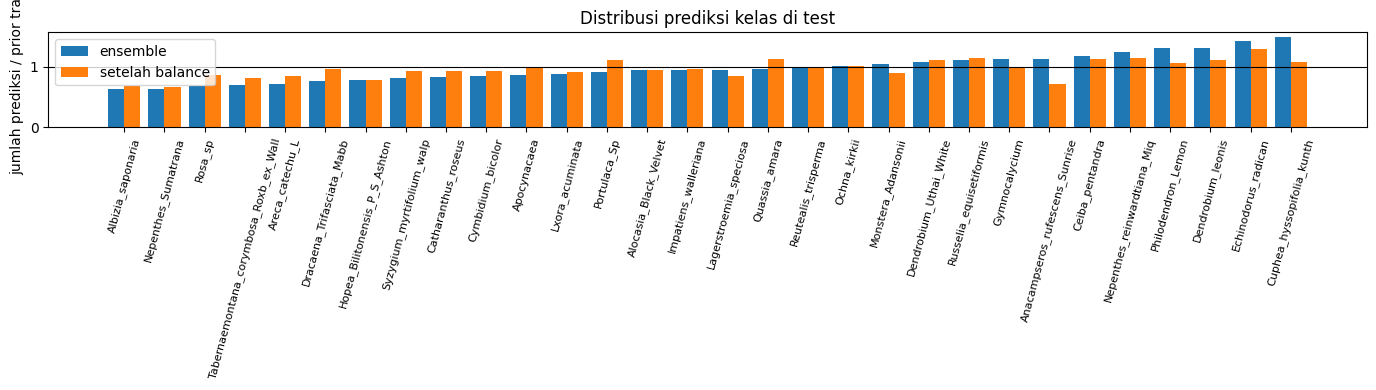

In [3]:
r0, r1 = count_ratio(P_test), count_ratio(P_test_bal); o = np.argsort(r0); x = np.arange(NC)
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(x - 0.2, r0[o], 0.4, label="ensemble"); ax.bar(x + 0.2, r1[o], 0.4, label="setelah balance")
ax.axhline(1, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(NAMES[o], rotation=75, fontsize=8)
ax.set_ylabel("jumlah prediksi / prior train"); ax.set_title("Distribusi prediksi kelas di test"); ax.legend()
plt.tight_layout(); plt.show()

**Observasi:**
- Balance naikin OOF tipis: **0.7727 → 0.7764** (+0.004). Kecil, tapi labelnya gak dipakai sama sekali, jadi gak ada risiko bocor.
- Di test, kelas yang paling "kebanyakan" ditebak turun dari 1.50x ke 1.30x prior, dan 162 dari 2010 prediksi berubah.
- Efeknya numpuk sama manipulasi lain (lihat Bagian 3: res 320 dari 0.8089 jadi 0.8155 setelah balance). Jadi balance dipakai sebagai langkah terakhir di semua kandidat.

## Bagian 2 — Korupsi test yang mana yang paling bikin model ragu?

**Pertanyaan:** test punya macam-macam korupsi (abu-abu, border hitam, gelap/terang, blur, JPEG jelek). Label test gak ada, tapi kita bisa ukur **confidence** ensemble per jenis korupsi. Di val v4+rotasi labelnya ada, jadi bisa sekalian lihat **akurasi** per kelompok yang sama.

Fitur sederhana per gambar (dari cache 224 px):
- `abu`: beda antar channel kecil banget → gambar grayscale
- `hitam`: proporsi piksel hampir hitam (border, pojok rotasi, cutout)
- `terang`, `saturasi`: rata-rata kecerahan & saturasi
- `tajam`: variansi Laplacian (kecil = blur / JPEG rusak)

In [4]:
TEST = np.load(T.CACHE / "test.npy"); VROT = np.load(T.CACHE / "corr4r.npy"); CLEAN = np.load(T.CACHE / "clean.npy")

def feats(arr):
    a = arr.astype(np.float32)
    beda = np.abs(a[..., 0] - a[..., 1]).mean((1, 2)) + np.abs(a[..., 1] - a[..., 2]).mean((1, 2))
    sat = np.array([cv2.cvtColor(x, cv2.COLOR_RGB2HSV)[..., 1].mean() for x in arr])
    tajam = np.array([cv2.Laplacian(cv2.cvtColor(x, cv2.COLOR_RGB2GRAY), cv2.CV_32F).var() for x in arr])
    return pd.DataFrame(dict(abu=(beda < 4).astype(float), hitam=(arr.max(-1) < 16).mean((1, 2)),
                             terang=a.mean((1, 2, 3)), saturasi=sat, tajam=tajam))

F = {"train bersih": feats(CLEAN), "val v4+rot": feats(VROT), "test": feats(TEST)}
display(pd.DataFrame({k: v.mean() for k, v in F.items()}).round(3).rename_axis("rata-rata fitur"))

,train bersih,val v4+rot,test
rata-rata fitur,,,
abu,0.000,0.096,0.105
hitam,0.017,0.154,0.061
terang,106.303,93.243,98.671
saturasi,97.719,91.510,97.127
tajam,3272.216,1868.549,1506.968


In [5]:
conf, benar = P_test.max(1), (P_oof.argmax(1) == y)
EDGES = {"hitam": [0, 0.01, 0.05, 0.15, 1]}
tab = []
for col in ["abu", "hitam", "terang", "saturasi", "tajam"]:
    e = np.array(EDGES.get(col, np.unique(np.quantile(F["test"][col], [0, .25, .5, .75, 1]))), float)
    if col == "abu": e = np.array([0, 0.5, 1.0])
    e[0], e[-1] = -np.inf, np.inf  # batas kelompok dari kuartil TEST, dipakai juga ke val
    bt, bv = pd.cut(F["test"][col], e).astype(str), pd.cut(F["val v4+rot"][col], e).astype(str)
    t = pd.DataFrame(dict(n_test=pd.Series(conf).groupby(bt.values).size(), conf_test=pd.Series(conf).groupby(bt.values).mean(),
                          n_val=pd.Series(benar).groupby(bv.values).size(), akurasi_val=pd.Series(benar).groupby(bv.values).mean()))
    t.index = [f"{col} {i}" for i in t.index]; tab.append(t)
display(pd.concat(tab).round(3))

,n_test,conf_test,n_val,akurasi_val
"abu (-inf, 0.5]",1798,0.512,2726,0.782
"abu (0.5, inf]",212,0.421,288,0.618
"hitam (-inf, 0.01]",836,0.536,1118,0.826
"hitam (0.01, 0.05]",489,0.475,313,0.741
"hitam (0.05, 0.15]",393,0.473,222,0.748
"hitam (0.15, inf]",292,0.495,1361,0.727
"terang (-inf, 75.912]",503,0.482,971,0.754
"terang (116.723, inf]",503,0.469,752,0.769
"terang (75.912, 95.366]",502,0.535,646,0.762
"terang (95.366, 116.723]",502,0.524,645,0.788


**Observasi:**
- **Gambar abu-abu** (10.5% test, 9.6% val) paling lemah: akurasi val cuma 0.618 (vs 0.782 yang berwarna), confidence test 0.42 (vs 0.51). Wajar, warna itu petunjuk besar buat bedain spesies.
- **Blur/JPEG jelek** juga lemah: kuartil paling gak tajam di test confidence-nya 0.373, dan di val akurasinya 0.678. Yang penting: **test jauh lebih blur dari val** (rata-rata ketajaman 1507 vs 1869; di kelompok paling blur ada 503 gambar test tapi cuma 245 val). Jadi val kita kurang mewakili gambar test yang paling rusak.
- Saturasi rendah juga lemah (akurasi val 0.700).
- Piksel hitam: val malah jauh lebih banyak (15.4%) daripada test (6.1%), karena pojok rotasi di val sebagian diisi hitam. Kelihatannya rotasi di test jarang ninggalin pojok hitam.
- Kandidat perbaikan training ke depan: augmentasi blur/downscale & grayscale lebih sering, plus val yang lebih blur biar mirip test.

## Bagian 3 — Manipulasi gambar saat inference

**Pertanyaan:** kalau gambar val/test "dibersihkan" dulu sebelum masuk model, F1 naik gak? Yang dicoba:
- **gray-world**: buang tint warna (rata-rata tiap channel disamain)
- **CLAHE**: naikin kontras lokal di channel L (LAB)
- **stretch 1–99**: autocontrast per channel
- **autocrop**: potong border hitam persegi, lalu resize balik
- **resolusi 224–352**: model dilatih pakai RandomResizedCrop, jadi objek di train keliatan lebih "besar" daripada di val/test. Ngetes di resolusi lebih tinggi kadang ngebantu (efek "FixRes").

Val v4+rotasi untuk tiap resolusi dibuat ulang dari gambar asli dengan seed yang sama persis kayak cache 224, jadi korupsi & sudutnya identik. "res 224" di sini = cache buatan ulang, jadi skornya harus sama dengan "tanpa (224)" (cek kewarasan).

In [6]:
def val_rot_size(args):  # sama dengan T.val_rot (seed per gambar), cuma ukuran akhirnya beda
    path, seed, size = args
    rng = np.random.RandomState(seed + 1_000_003)
    img = T.rot_img(dq.read_rgb(path), rng.uniform(-180, 180), rng.rand() < 0.5)
    np.random.seed(seed); dq.corrupt_v4.set_random_seed(seed)
    return dq.squash(dq.corrupt_v4(image=img)["image"], size)

SIZES = [224, 256, 288, 320, 352]
VAL_S, TEST_S = {}, {}
for s in SIZES:
    cv, ct = T.CACHE / f"corr4r_{s}.npy", T.CACHE / f"test_{s}.npy"
    if not cv.exists():  # fork sebelum CUDA dipakai di notebook ini
        t0 = time.time()
        with mp.get_context("fork").Pool(64) as pool:
            T.save_npy(cv, np.stack(pool.map(val_rot_size, [(p, k, s) for k, p in enumerate(TRP)], chunksize=4)))
        print(f"val v4+rot {s}px: {time.time() - t0:.0f}s")
    if not ct.exists():
        with ThreadPoolExecutor(64) as ex:
            T.save_npy(ct, np.stack(list(ex.map(lambda p: dq.squash(dq.read_rgb(p), s), TEP))))
    VAL_S[s], TEST_S[s] = np.load(cv, mmap_mode="r"), np.load(ct, mmap_mode="r")
print("cache 224 buatan ulang vs cache train.py | val identik:", float((VAL_S[224] == VROT).mean()), "| test identik:", float((TEST_S[224] == TEST).mean()))

cache 224 buatan ulang vs cache train.py | val identik: 1.0 | test identik: 1.0


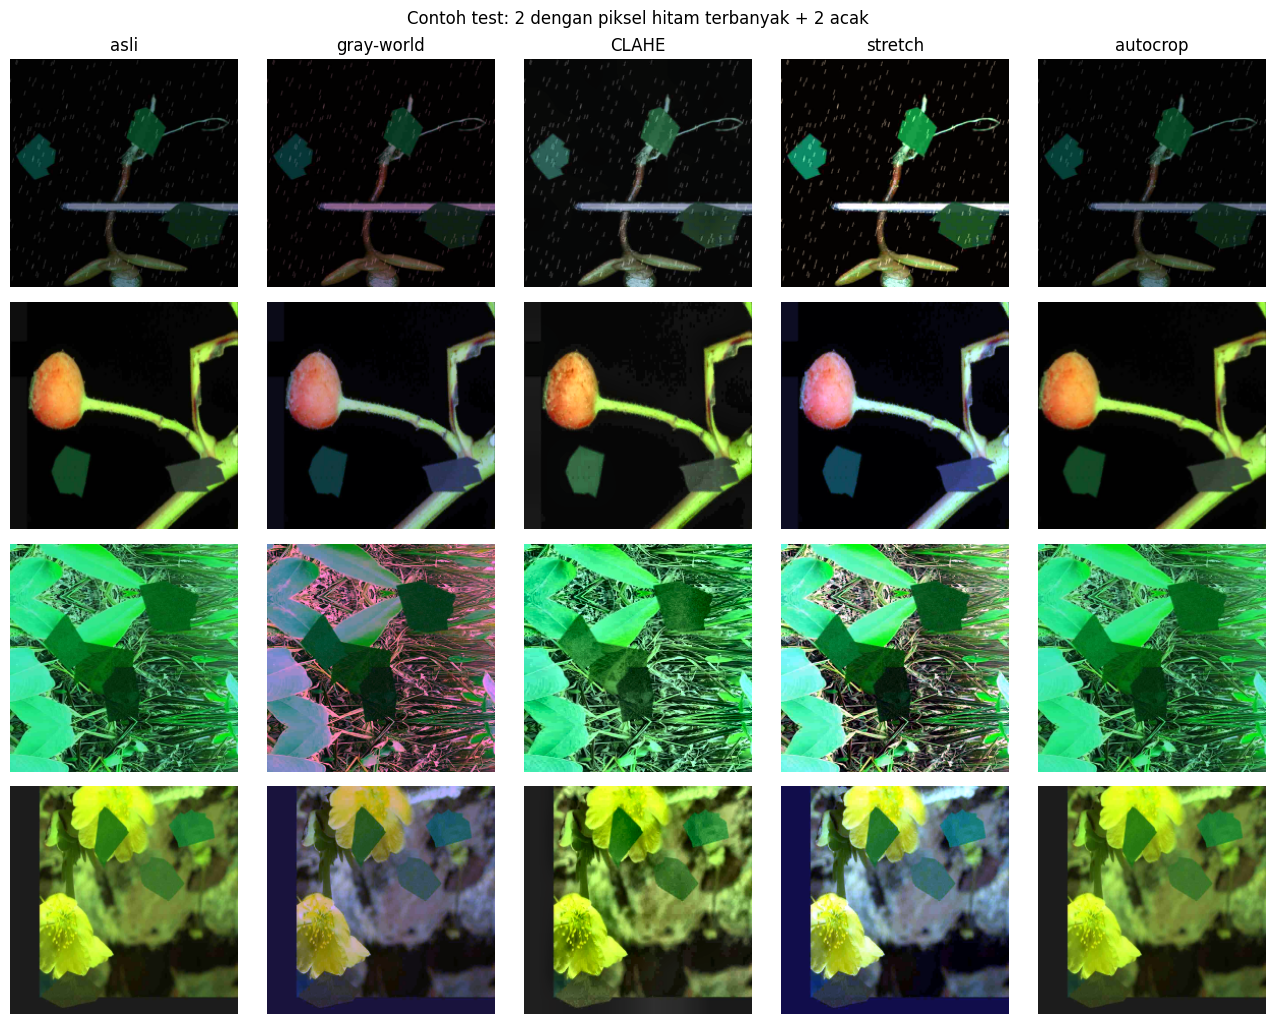

In [7]:
def grayworld(x):
    a = x.astype(np.float32); m = a.reshape(-1, 3).mean(0) + 1e-3
    return np.clip(a * (m.mean() / m), 0, 255).astype(np.uint8)

def clahe(x):
    lab = cv2.cvtColor(x, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def stretch(x):  # autocontrast per channel, persentil 1-99
    a = x.astype(np.float32); lo, hi = np.percentile(a.reshape(-1, 3), [1, 99], axis=0)
    return np.clip((a - lo) / np.maximum(hi - lo, 1) * 255, 0, 255).astype(np.uint8)

def autocrop(x, thr=16):  # potong baris/kolom pinggir yang full hitam
    m = x.max(-1) > thr; r, c = np.where(m.any(1))[0], np.where(m.any(0))[0]
    if len(r) == 0: return x
    h, w = x.shape[:2]; y0, y1, x0, x1 = r[0], r[-1] + 1, c[0], c[-1] + 1
    if (y1 - y0) * (x1 - x0) > 0.97 * h * w or (y1 - y0) < 0.3 * h or (x1 - x0) < 0.3 * w: return x
    return cv2.resize(x[y0:y1, x0:x1], (w, h), interpolation=cv2.INTER_AREA)

rng = np.random.RandomState(0)
idx = list(F["test"].hitam.nlargest(2).index) + list(rng.choice(len(TEST), 2, replace=False))
fns = {"asli": None, "gray-world": grayworld, "CLAHE": clahe, "stretch": stretch, "autocrop": autocrop}
fig, axs = plt.subplots(len(idx), len(fns), figsize=(2.6 * len(fns), 2.6 * len(idx)))
for r, i in enumerate(idx):
    for c, (n, fn) in enumerate(fns.items()):
        axs[r, c].imshow(TEST[i] if fn is None else fn(TEST[i])); axs[r, c].axis("off")
        if r == 0: axs[r, c].set_title(n)
plt.suptitle("Contoh test: 2 dengan piksel hitam terbanyak + 2 acak"); plt.tight_layout(); plt.show()

In [8]:
def load_models(name):
    ms = []
    for f in range(5):
        d = T.RUNS / f"{name}_f{f}"; m = T.make_model(json.loads((d / "cfg.json").read_text()), NC)
        m.load_state_dict(torch.load(d / "model.pt", map_location="cpu"))
        ms.append(m.to(T.DEV).to(memory_format=torch.channels_last).eval())
    return ms
NETS = {m: load_models(m) for m in MODELS}

def apply(arr, fn): return arr if fn is None else np.stack([fn(x) for x in arr])

def oof_probs(arr, fn=None):  # tiap model cuma nebak fold val-nya sendiri, terus dirata-rata antar resep
    X = apply(arr, fn); out = np.zeros((len(X), NC), np.float32)
    for m in MODELS:
        for f, net in enumerate(NETS[m]):
            out[folds == f] += T.predict(net, X[folds == f], "flip") / len(MODELS)
    return out

def test_probs(arr, fn=None):
    X = apply(arr, fn)
    return np.mean([T.predict(net, X, "flip") for m in MODELS for net in NETS[m]], 0)

EXP = {  # nama: (val, test, fungsi)
    "tanpa (224)": (VROT, TEST, None), "gray-world": (VROT, TEST, grayworld), "CLAHE": (VROT, TEST, clahe),
    "stretch 1-99": (VROT, TEST, stretch), "autocrop": (VROT, TEST, autocrop),
    **{f"res {s}": (VAL_S[s], TEST_S[s], None) for s in SIZES}}
PO, res = {}, []
for k, (va, _, fn) in EXP.items():
    t0 = time.time(); PO[k] = oof_probs(va, fn)
    res.append(dict(manipulasi=k, oof_f1=f1(PO[k]), oof_f1_balance=f1(balance(PO[k], prior)), detik=round(time.time() - t0)))
print("cek: OOF tanpa manipulasi harus sama dengan file OOF ->", round(f1(PO["tanpa (224)"]), 4), "vs", round(f1(P_oof), 4))
display(pd.DataFrame(res).set_index("manipulasi").round(4))

cek: OOF tanpa manipulasi harus sama dengan file OOF -> 0.7727 vs 0.7727


,oof_f1,oof_f1_balance,detik
manipulasi,,,
tanpa (224),0.7727,0.7764,2
gray-world,0.6492,0.6602,5
CLAHE,0.6457,0.6680,4
stretch 1-99,0.7244,0.7323,10
autocrop,0.7592,0.7615,5
res 224,0.7727,0.7764,1
res 256,0.8016,0.8031,2
res 288,0.8100,0.8135,2
res 320,0.8089,0.8155,3


In [9]:
# gabungan: rata-rata prob "tanpa" + manipulasi lain (semacam TTA)
base = PO["tanpa (224)"]
combo = {f"tanpa + {k}": (base + v) / 2 for k, v in PO.items() if k != "tanpa (224)"}
cands = {**PO, **combo}
tbl = pd.DataFrame({k: dict(oof_f1=f1(v), oof_f1_balance=f1(balance(v, prior))) for k, v in cands.items()}).T
tbl = tbl.sort_values("oof_f1_balance", ascending=False); display(tbl.round(4))

,oof_f1,oof_f1_balance
res 320,0.8089,0.8155
tanpa + res 352,0.8095,0.8152
res 288,0.8100,0.8135
res 352,0.8057,0.8127
tanpa + res 320,0.8057,0.8106
res 256,0.8016,0.8031
tanpa + res 288,0.7966,0.8025
tanpa + res 256,0.7884,0.7939
tanpa + stretch 1-99,0.7690,0.7766
tanpa (224),0.7727,0.7764


**Observasi:**
- **Manipulasi warna/kontras malah ngerusak parah:** gray-world −0.12, CLAHE −0.13, stretch −0.05. Model udah belajar tahan tint (dari corrupt_v4) dan tetep butuh info warna, jadi "membersihkan" warna justru ngilangin petunjuk. Autocrop juga turun dikit (−0.013).
- **Resolusi saat inference ngebantu banget:** 224 → 0.773, 256 → 0.802, **288 → 0.810, 320 → 0.809**, 352 → 0.806. Puncaknya di 288–320, jadi bukan kebetulan satu titik.
- Kenapa: waktu training kita pakai RandomResizedCrop (scale 0.25–1), jadi objek di train rata-rata keliatan lebih "besar" dari aslinya. Pas test di resolusi lebih tinggi, ukuran objeknya jadi mirip yang dilihat model waktu training (efek "FixRes", Touvron dkk. 2019).
- Catatan: di run pertama, "res 256" dibuat dengan resize 288 → 256 dan skornya cuma 0.743. Setelah dibuat langsung dari gambar asli jadi 0.802. Jadi resize dua kali itu ngerusak; semua cache resolusi sekarang dibuat langsung dari gambar asli.
- "res 224" buatan ulang identik 100% dengan cache `train.py` dan skornya sama persis, jadi perbandingannya adil.

## Bagian 4 — Ada test yang satu scene dengan train?

**Pertanyaan:** train punya 237 grup scene (foto dari sesi/tanaman yang sama). Kalau sebagian gambar test ternyata foto lain dari scene yang sama, labelnya bisa "dipinjam" dari train.

Caranya pakai **SIFT** (tahan rotasi, jadi cocok buat test yang diputar 0–360°):
1. SIFT maks 300 keypoint per gambar (sisi panjang diperkecil ke 400 px).
2. Tiap keypoint query dicari tetangga terdekatnya di semua keypoint train (brute force di GPU), lalu Lowe ratio test 0.75.
3. Untuk 3 gambar train dengan vote terbanyak, cek konsistensi geometri pakai RANSAC (rotasi + skala + geser). Jumlah **inlier** = seberapa yakin dua foto itu scene yang sama.

Biar tahu seberapa bisa dipercaya: hal yang sama dijalankan **train vs train** (tanpa dirinya sendiri). Dari situ kelihatan, kalau inlier ≥ k, seberapa sering labelnya sama.

In [10]:
def sift_feat(p, side=400):
    g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE); s = side / max(g.shape)
    if s < 1: g = cv2.resize(g, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    kp, d = cv2.SIFT_create(nfeatures=300).detectAndCompute(g, None)
    if d is None: return np.zeros((0, 2), np.float32), np.zeros((0, 128), np.float32)
    return np.array([k.pt for k in kp], np.float32), d.astype(np.float32)

t0 = time.time()
with ThreadPoolExecutor(64) as ex:
    KTR, KTE = list(ex.map(sift_feat, TRP)), list(ex.map(sift_feat, TEP))
print(f"SIFT {time.time() - t0:.0f}s | keypoint rata-rata train {np.mean([len(k[0]) for k in KTR]):.0f}, test {np.mean([len(k[0]) for k in KTE]):.0f}")

own = np.concatenate([np.full(len(k[0]), i) for i, k in enumerate(KTR)])   # keypoint -> index gambar train
kidx = np.concatenate([np.arange(len(k[0])) for k in KTR])                   # keypoint -> nomor keypoint di gambarnya
DB = torch.from_numpy(np.concatenate([k[1] for k in KTR])).to(T.DEV); DBn = (DB ** 2).sum(1)
print("database keypoint train:", len(own))

def nn_query(Q, k=8):
    q = torch.from_numpy(Q).to(T.DEV)
    d2 = (q ** 2).sum(1, keepdim=True) + DBn[None] - 2 * q @ DB.T
    d, j = d2.topk(k, largest=False)
    return d.clamp_min(0).sqrt().cpu().numpy(), j.cpu().numpy()

def match_image(kq, exclude=-1, ratio=0.75):
    """-> (index train terbaik, jumlah match lolos ratio test, inlier RANSAC terbanyak)"""
    pts, D = kq
    if len(D) < 8: return -1, 0, 0
    d, j = nn_query(D); o = own[j]
    gq, gt = [], []
    for r in range(len(D)):
        v = np.flatnonzero(o[r] != exclude)
        if len(v) >= 2 and d[r, v[0]] < ratio * d[r, v[1]]: gq.append(r); gt.append(j[r, v[0]])
    if len(gq) < 4: return -1, len(gq), 0
    gq, gt = np.array(gq), np.array(gt); img = own[gt]
    best, best_in = -1, 0
    for c in np.bincount(img).argsort()[::-1][:3]:
        s = img == c
        if s.sum() < 4: continue
        _, inl = cv2.estimateAffinePartial2D(pts[gq[s]], KTR[c][0][kidx[gt[s]]], method=cv2.RANSAC, ransacReprojThreshold=8.0)
        n = int(inl.sum()) if inl is not None else 0
        if n > best_in: best, best_in = int(c), n
    return best, len(gq), best_in

t0 = time.time()
MTR = pd.DataFrame([match_image(KTR[i], exclude=i) for i in range(len(KTR))], columns=["idx", "good", "inlier"])
MTE = pd.DataFrame([match_image(k) for k in KTE], columns=["idx", "good", "inlier"])
print(f"matching {time.time() - t0:.0f}s")

SIFT 5s | keypoint rata-rata train 297, test 286
database keypoint train: 894340
matching 97s


,min_inlier,train_cakupan,train_label_sama,train_grup_sama,test_cakupan,test_n,test_setuju_model
0,5,0.280,1.0,0.454,0.128,258,0.849
1,8,0.219,1.0,0.513,0.087,174,0.885
2,12,0.168,1.0,0.564,0.057,115,0.896
3,20,0.110,1.0,0.619,0.031,62,0.887
4,30,0.074,1.0,0.644,0.019,38,0.868
5,50,0.036,1.0,0.598,0.005,10,1.000


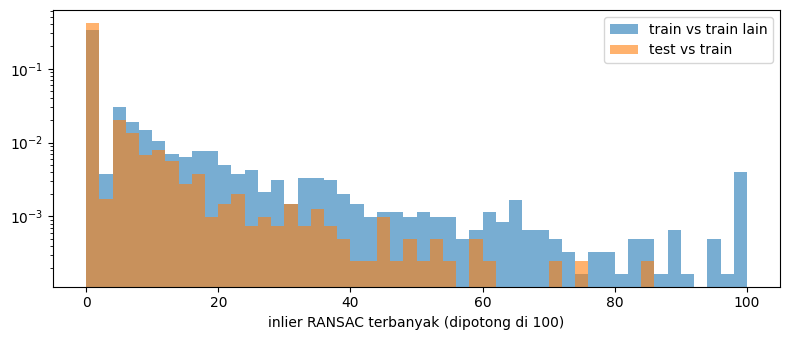

In [11]:
grp = pd.read_csv(T.CACHE / "scene_folds.csv").group_id.values
ok_tr = MTR.idx >= 0
MTR["label_sama"] = ok_tr & (y[MTR.idx.clip(0)] == y)
MTR["grup_sama"] = ok_tr & (grp[MTR.idx.clip(0)] == grp)
MTE["label_match"] = np.where(MTE.idx >= 0, y[MTE.idx.clip(0)], -1)
MTE["setuju_model"] = MTE.label_match == P_test.argmax(1)
TH = [5, 8, 12, 20, 30, 50]
tab4 = pd.DataFrame([dict(min_inlier=t,
    train_cakupan=(MTR.inlier >= t).mean(), train_label_sama=MTR.label_sama[MTR.inlier >= t].mean(),
    train_grup_sama=MTR.grup_sama[MTR.inlier >= t].mean(),
    test_cakupan=(MTE.inlier >= t).mean(), test_n=int((MTE.inlier >= t).sum()),
    test_setuju_model=MTE.setuju_model[MTE.inlier >= t].mean()) for t in TH])
display(tab4.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
b = np.arange(0, 102, 2)
ax.hist(MTR.inlier.clip(0, 100), b, alpha=0.6, density=True, label="train vs train lain")
ax.hist(MTE.inlier.clip(0, 100), b, alpha=0.6, density=True, label="test vs train")
ax.set_yscale("log"); ax.set_xlabel("inlier RANSAC terbanyak (dipotong di 100)"); ax.legend(); plt.tight_layout(); plt.show()

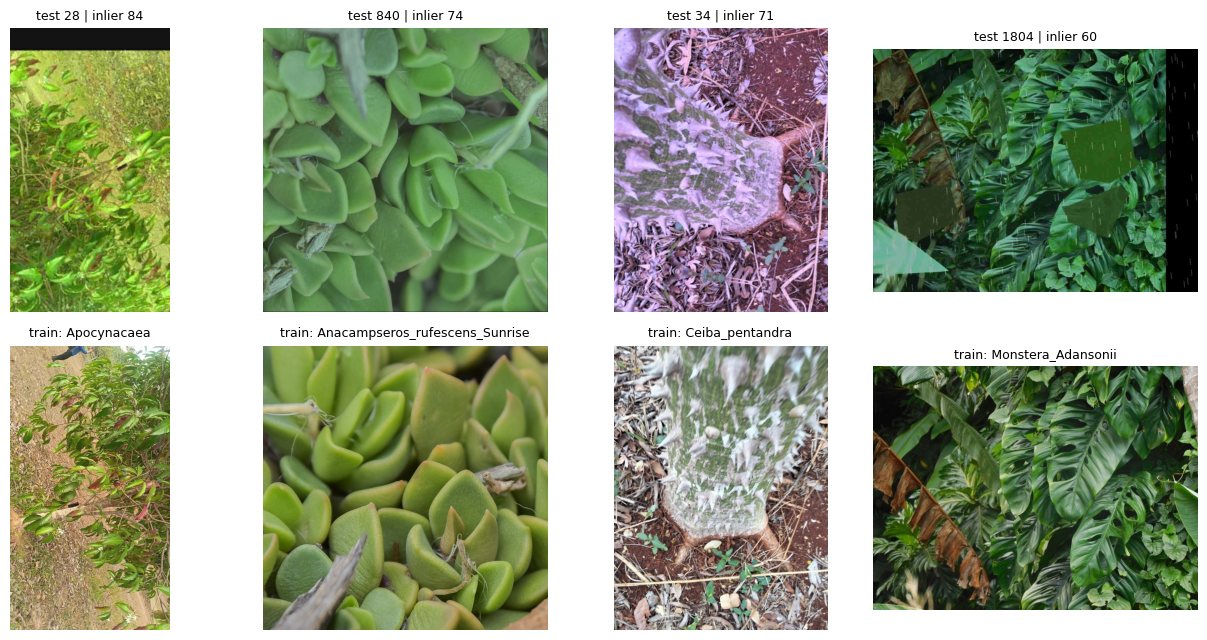

In [12]:
# contoh pasangan test-train dengan inlier tertinggi
top = MTE.sort_values("inlier", ascending=False).head(4)
fig, axs = plt.subplots(2, 4, figsize=(13, 6.5))
for c, (i, r) in enumerate(top.iterrows()):
    axs[0, c].imshow(dq.read_rgb(TEP[i])); axs[0, c].set_title(f"test {i} | inlier {r.inlier}", fontsize=9)
    axs[1, c].imshow(dq.read_rgb(TRP[r.idx])); axs[1, c].set_title(f"train: {NAMES[y[r.idx]]}", fontsize=9)
    axs[0, c].axis("off"); axs[1, c].axis("off")
plt.tight_layout(); plt.show()

**Observasi:**
- Train vs train: kalau inlier ≥ 5, labelnya **selalu sama (100%)**, dan ini kena di 28% gambar train. Menariknya, cuma 45–64% yang satu grup scene, jadi SIFT juga nemu foto spesies sama dari grup lain (lokasi/tanaman mirip).
- Test vs train: **12.8% test (258 gambar)** punya pasangan dengan inlier ≥ 5. Di gambar-gambar itu model udah setuju 85% dengan label pasangannya, jadi sisanya (sekitar 40-an gambar) yang bakal berubah.
- Hati-hati: presisi 100% itu diukur di pasangan train **bersih** vs train bersih. Test terkorupsi (rotasi, JPEG, tint), jadi match-nya lebih lemah dan presisinya bisa lebih rendah. Makanya SIFT dipisah jadi kandidat sendiri, biar efeknya kelihatan di LB.

## Bagian 5 — Submission kandidat

Ditulis ke `runs/` dengan sha 16 hex (format deskripsi Kaggle kita). Yang dikirim ke LB tetap keputusan manual.
- `manip_balance`: ensemble sekarang + balance (Bagian 1)
- `manip_best`: manipulasi terbaik dari Bagian 3 (+ balance kalau OOF-nya lebih tinggi)
- `manip_best_sift`: `manip_best` + label train dipinjam untuk test yang inlier-nya ≥ ambang yang presisinya ≥ 0.98 di train vs train

In [13]:
def write_sub(name, lab):
    s = pd.DataFrame({"id": sub.id, "label": np.asarray(lab).astype(int)})
    assert len(s) == len(sub) and (s.id.values == sub.id.values).all() and s.label.between(0, NC - 1).all()
    path = T.RUNS / f"{name}_submission.csv"; s.to_csv(path, index=False)
    base = pd.read_csv(T.RUNS / "ens_best_submission.csv").label.values
    return dict(file=path.name, sha=hashlib.sha256(path.read_bytes()).hexdigest()[:16], sama_dengan_ens_best=round(float(np.mean(s.label.values == base)), 4))

def test_of(k):  # k: satu manipulasi atau "tanpa + X"
    parts = ["tanpa (224)", k.split(" + ", 1)[1]] if k.startswith("tanpa + ") else [k]
    return np.mean([test_probs(EXP[q][1], EXP[q][2]) for q in parts], 0)

print("cek: prob test tanpa manipulasi vs file ptest, beda maks =", float(np.abs(test_of("tanpa (224)") - P_test).max()))
best = tbl.index[0]; use_bal = tbl.loc[best, "oof_f1_balance"] > tbl.loc[best, "oof_f1"]
PT_best = test_of(best); PT_best = balance(PT_best, prior) if use_bal else PT_best
lab_best = PT_best.argmax(1)

ok = tab4[tab4.train_label_sama >= 0.98]
TSTAR = int(ok.min_inlier.min()) if len(ok) else None
lab_sift = lab_best.copy()
if TSTAR is not None:
    m = (MTE.inlier >= TSTAR).values; lab_sift[m] = MTE.label_match.values[m]
print(f"terbaik: {best} | balance: {use_bal} | ambang SIFT: {TSTAR} | label diganti SIFT: {int((lab_sift != lab_best).sum())}")

SUBS = pd.DataFrame([dict(kandidat="manip_balance", **write_sub("manip_balance", P_test_bal.argmax(1))),
                     dict(kandidat=f"manip_best ({best}{' + balance' if use_bal else ''})", **write_sub("manip_best", lab_best)),
                     dict(kandidat=f"manip_best_sift (inlier >= {TSTAR})", **write_sub("manip_best_sift", lab_sift))])
display(SUBS)

cek: prob test tanpa manipulasi vs file ptest, beda maks = 0.0003796517848968506


~/inahuy/train.py:221: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = norm(torch.from_numpy(np.ascontiguousarray(arr[i:i + bs])).to(DEV).permute(0, 3, 1, 2))


terbaik: res 320 | balance: True | ambang SIFT: 5 | label diganti SIFT: 44


,kandidat,file,sha,sama_dengan_ens_best
0,manip_balance,manip_balance_submission.csv,eb26528c119c5ce5,0.9194
1,manip_best (res 320 + balance),manip_best_submission.csv,69be8bb4b9dd7b74,0.7930
2,manip_best_sift (inlier >= 5),manip_best_sift_submission.csv,8a04e7a7ca571ee4,0.7940


## Bagian 6 — Model baru (RegNet, EfficientNet) + trik resolusi

**Pertanyaan:** 4 model hasil screening (regnety_008, regnety_016, efficientnet_b0, efficientnet_b2) baru dilatih di **fold 0**. Sendirian mereka kalah dari r18d, tapi:
1. Apakah trik resolusi tinggi juga ngebantu mereka?
2. Kalau digabung ke ensemble r18d + e600, nambah gak? (Model yang beda arsitektur kadang ngebantu ensemble walau sendirinya lebih lemah.)

Semua dihitung di **fold 0 saja (614 gambar)**, karena model baru belum punya fold lain. Selisih di bawah ~0.01–0.02 masih bisa noise.

In [14]:
NEW = ["R_regnety_008", "R_regnety_016", "R_efficientnet_b0", "R_efficientnet_b2"]
va0, y0 = folds == 0, y[folds == 0]

def net_f0(name):
    d = T.RUNS / f"{name}_f0"; m = T.make_model(json.loads((d / "cfg.json").read_text()), NC)
    m.load_state_dict(torch.load(d / "model.pt", map_location="cpu"))
    return m.to(T.DEV).to(memory_format=torch.channels_last).eval()

F0 = {**{m: NETS[m][0] for m in MODELS}, **{m: net_f0(m) for m in NEW}}
P0 = {(m, s): T.predict(net, np.asarray(VAL_S[s][va0]), "flip") for m, net in F0.items() for s in SIZES}
tab6 = pd.DataFrame({m: {s: f1(P0[(m, s)], y0) for s in SIZES} for m in F0}).T
tab6.columns = [f"res {s}" for s in SIZES]
print("F1 fold 0 per model per resolusi (res 224 harus sama dengan done.json: r18d 0.7693, regnety_008 0.7030, effnet_b0 0.6780)")
display(tab6.round(4))

F1 fold 0 per model per resolusi (res 224 harus sama dengan done.json: r18d 0.7693, regnety_008 0.7030, effnet_b0 0.6780)


,res 224,res 256,res 288,res 320,res 352
R_r18d,0.7693,0.7789,0.7844,0.7971,0.7907
R_e600,0.7585,0.7798,0.7989,0.8152,0.8187
R_regnety_008,0.7030,0.7154,0.7354,0.7367,0.7464
R_regnety_016,0.7023,0.7388,0.7599,0.7595,0.7569
R_efficientnet_b0,0.6767,0.7314,0.7382,0.7534,0.7500
R_efficientnet_b2,0.6460,0.7037,0.7207,0.7218,0.7106


In [15]:
def ens0(ms, s): return np.mean([P0[(m, s)] for m in ms], 0)
base = ["R_r18d", "R_e600"]
combos = {"r18d + e600": base, **{f"r18d + e600 + {m[2:]}": base + [m] for m in NEW},
          "r18d + e600 + regnety_008 + regnety_016": base + NEW[:2], "r18d + e600 + semua baru": base + NEW,
          "4 model baru saja": NEW}
rows = [dict(ensemble=k, res=s, f1=f1(ens0(ms, s), y0), f1_balance=f1(balance(ens0(ms, s), prior), y0))
        for s in [224, 288, 320] for k, ms in combos.items()]
r6 = pd.DataFrame(rows)
display(r6.pivot(index="ensemble", columns="res", values="f1").loc[list(combos)].add_prefix("res ").round(4))
print("dengan balance:")
display(r6.pivot(index="ensemble", columns="res", values="f1_balance").loc[list(combos)].add_prefix("res ").round(4))

res,res 224,res 288,res 320
ensemble,,,
r18d + e600,0.7788,0.8238,0.8255
r18d + e600 + regnety_008,0.7683,0.8226,0.8334
r18d + e600 + regnety_016,0.7938,0.8160,0.8307
r18d + e600 + efficientnet_b0,0.7805,0.8192,0.8231
r18d + e600 + efficientnet_b2,0.7717,0.8212,0.8272
r18d + e600 + regnety_008 + regnety_016,0.7758,0.8282,0.8333
r18d + e600 + semua baru,0.7790,0.8123,0.8136
4 model baru saja,0.7441,0.7867,0.7910


dengan balance:


res,res 224,res 288,res 320
ensemble,,,
r18d + e600,0.7969,0.8247,0.8291
r18d + e600 + regnety_008,0.7861,0.8378,0.8483
r18d + e600 + regnety_016,0.7966,0.8258,0.8373
r18d + e600 + efficientnet_b0,0.7968,0.8323,0.8366
r18d + e600 + efficientnet_b2,0.7894,0.8198,0.8203
r18d + e600 + regnety_008 + regnety_016,0.7925,0.8199,0.8342
r18d + e600 + semua baru,0.7689,0.8166,0.8185
4 model baru saja,0.7435,0.7883,0.7896


**Observasi:** _(diisi setelah dijalankan)_

## Kesimpulan

| Ide | Hasil di OOF | Dipakai? |
|---|---|---|
| Balance prediksi kelas | +0.004 (0.7727 → 0.7764) | ya, di semua kandidat |
| Gray-world / CLAHE / stretch | −0.05 s.d. −0.13 | tidak |
| Autocrop border hitam | −0.013 | tidak |
| **Resolusi inference 288–320** | **+0.037** (0.773 → 0.810) | **ya** |
| Res 320 + balance | 0.8155 (terbaik) | ya → `manip_best` |
| Pinjam label train via SIFT (inlier ≥ 5) | gak bisa diukur di OOF; ganti 44 label test | kandidat terpisah |

**Urutan submit ke LB yang disarankan:**
1. `manip_best` (res 320 + balance). Ini perubahan terbesar: cuma 79% prediksinya sama dengan `ens_best` (LB 0.80694).
2. `manip_best_sift`. Bandingin sama no. 1 buat tahu SIFT ngebantu atau nggak.
3. `manip_balance` kalau mau ngukur efek balance sendirian.

**Langkah berikutnya kalau resolusi tinggi kebukti di LB:** latih ulang (atau fine-tune beberapa epoch) di resolusi 288–320, karena sekarang modelnya masih dilatih di 224. Dari Bagian 2, augmentasi blur/grayscale yang lebih sering juga layak dicoba.